# BÁO CÁO TỔNG KẾT ĐỒ ÁN MACHINE LEARNING (LAB 2)
## Đề tài: Dự đoán Doanh số Bán lẻ BigMart (Item_Outlet_Sales)
**Học viên thực hiện:** Nhóm 05  
**Kiến trúc:** Pipeline 4 Pha khép kín (End-to-End Modular ML Pipeline)  
**Tiêu chuẩn khoa học:** Triệt tiêu hoàn toàn rò rỉ dữ liệu (Anti-Data Leakage), Độc lập mã nguồn (Decoupled Architecture), Giải thích mô hình (Explainable AI - XAI).


---
## 1. TỔNG QUAN ĐỀ TÀI & CẤU TRÚC THƯ MỤC DỰ ÁN

### 1.1. Bài toán kinh doanh & Mục tiêu đề tài
Dự án tập trung vào bài toán **Hồi quy dữ liệu bảng (Tabular Regression)** nhằm dự đoán doanh thu bán hàng thực tế (`Item_Outlet_Sales`) của từng mặt hàng tại các chi nhánh cửa hàng khác nhau thuộc chuỗi bán lẻ **BigMart**.
* **Đầu vào (Input):** Các thuộc tính của sản phẩm (khối lượng, giá niêm yết MRP, tỷ lệ trưng bày, loại hàng, hàm lượng chất béo) và đặc trưng của cửa hàng (năm thành lập, quy mô diện tích, phân cấp đô thị, loại hình siêu thị).
* **Đầu ra (Output):** Doanh số kỳ vọng $\hat{y}$ (USD) và chuỗi điều kiện logic rẽ nhánh giải thích lý do dự báo.

### 1.2. Giới thiệu Bộ dữ liệu BigMart Sales (BigMart Sales Dataset)
Bộ dữ liệu được thu thập và xác thực từ [Kaggle BigMart Sales Dataset](https://www.kaggle.com/datasets/yasserh/bigmartsalesdataset) (ghi nhận chi tiết tại notebook `01_collection.ipynb` và metadata `source.json`). 

* **Quy mô tập dữ liệu:** Gồm **8,523 bản ghi** tương ứng với các giao dịch sản phẩm tại các chi nhánh cửa hàng, bao gồm **1,559 sản phẩm độc nhất** (`Item_Identifier`) được phân phối qua **10 chi nhánh cửa hàng** (`Outlet_Identifier`). Hoàn toàn không có dòng trùng lặp (`duplicates = 0`).
* **Chi tiết 12 thuộc tính ban đầu (Schema):**

| Nhóm thuộc tính | Tên thuộc tính | Kiểu dữ liệu | Mô tả ý nghĩa thực tế & Tình trạng dữ liệu |
| :--- | :--- | :---: | :--- |
| **Sản phẩm (Product)** | `Item_Identifier` | Chuỗi / ID | Mã định danh duy nhất của sản phẩm (ví dụ: `FDA15`, `DRC01`). |
| | `Item_Weight` | Số thực (Float) | Khối lượng sản phẩm (kg). Chứa **1,463 giá trị khuyết** (~17.17%). |
| | `Item_Fat_Content` | Phân loại | Hàm lượng chất béo. Chứa các nhãn viết tắt không đồng nhất (`LF`, `low fat`, `reg`). |
| | `Item_Visibility` | Số thực (Float) | Tỷ lệ diện tích trưng bày trên quầy kệ [0, 1]. Có **526 mẫu ghi nhận giá trị 0** (bất thường thực tế). |
| | `Item_Type` | Phân loại | 16 danh mục nhóm hàng (Dairy, Soft Drinks, Meat, Fruits & Vegetables,...). |
| | `Item_MRP` | Số thực (Float) | Giá bán lẻ niêm yết tối đa (Maximum Retail Price), dao động từ 31.29 đến 266.89 USD. |
| **Cửa hàng (Store)** | `Outlet_Identifier` | Chuỗi / ID | Mã định danh chi nhánh cửa hàng (10 chi nhánh từ `OUT010` đến `OUT049`). |
| | `Outlet_Establishment_Year` | Số nguyên | Năm thành lập chi nhánh (từ năm 1985 đến 2009). Cần trích xuất thành tuổi hoạt động `Outlet_Age`. |
| | `Outlet_Size` | Phân loại | Quy mô diện tích chi nhánh (`Small`, `Medium`, `High`). Chứa **2,410 giá trị khuyết** (~28.28%). |
| | `Outlet_Location_Type` | Phân loại | Phân cấp vị trí đô thị đặt cửa hàng (`Tier 1`, `Tier 2`, `Tier 3`). |
| | `Outlet_Type` | Phân loại | Loại hình kinh doanh: Tiệm tạp hóa (`Grocery Store`) và Siêu thị các cấp (`Supermarket Type 1, 2, 3`). |
| **Biến mục tiêu (Target)** | `Item_Outlet_Sales` | Số thực (Float) | **Doanh số bán hàng thực tế tại cửa hàng** (USD). Biến liên tục dương > 0, phân phối lệch phải. |

### 1.3. Cấu trúc chi tiết thư mục dự án (Repository & Folder Structure)
Dự án được cấu trúc theo chuẩn công nghiệp (Production Data Science Structure), phân định tuyệt đối giữa dữ liệu, tài liệu, sổ tay phân tích và mã nguồn vận hành:

```text
GR_05_Lab_2/
├── requirements.txt
├── .vscode/
│   └── settings.json
├── data/
│   └── BigMart_Sales/
│       ├── raw/
│       │   ├── bigmart.csv
│       │   └── source.json
│       └── processed/
│           ├── bigmart_clean.csv
│           ├── preprocessing.json
│           ├── split_indices.csv
│           ├── test_processed.csv
│           ├── train_processed.csv
│           ├── val_processed.csv
│           ├── X_test.csv
│           ├── X_train.csv
│           ├── X_validation.csv
│           ├── y_test.csv
│           ├── y_train.csv
│           └── y_validation.csv
├── docs/
│   ├── Description.md
│   ├── Design.md
│   └── Algorithms/
│       ├── Decision_Tree.md
│       └── Linear_Regression.md
├── notebooks/
│   ├── 01_collection.ipynb
│   ├── 02_EDA.ipynb
│   └── report.ipynb
├── outputs/
│   ├── decision_tree_trained_model.json
│   ├── linear_regression_trained_model.json
│   ├── linear_regression_training_details.json
│   ├── models_evaluation_summary.json
│   ├── sample_inference_predictions.json
│   └── figures/
│       ├── actual_vs_predicted.png
│       ├── feature_importance.png
│       ├── model_comparison.png
│       └── residual_analysis.png
└── src/
    ├── __init__.py
    ├── data_loader.py
    ├── evaluate.py
    ├── inference.py
    ├── models.py
    ├── train.py
    └── visualization.py
```

### 1.4. Nguyên tắc vàng về chống rò rỉ dữ liệu (Anti-Data Leakage)
Dự án áp dụng triệt để nguyên lý: **Phân chia 3 tập Train (70%) - Validation (15%) - Test (15%) TRƯỚC KHI thực hiện bất kỳ phép biến đổi có trạng thái nào**. Toàn bộ giá trị điền khuyết (median cân nặng, mode quy mô) và từ điển mã hóa One-Hot chỉ được học duy nhất trên tập Train, sau đó đóng băng và áp dụng thụ động sang Validation và Test.


In [1]:
import os
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Thiết lập đường dẫn thư mục gốc repo
ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Không tìm thấy thư mục gốc repository chứa 'src'.")
    ROOT = ROOT.parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

print(f"[*] Thư mục gốc dự án: {ROOT}")
print(f"[*] Phiên bản Python  : {sys.version.split()[0]}")
print(f"[*] Phiên bản Pandas  : {pd.__version__}")
print(f"[*] Phiên bản NumPy   : {np.__version__}")


[*] Thư mục gốc dự án: C:\Users\Nguyen Thanh Huy\Documents\Machine_Learning\GR_05_Lab_2
[*] Phiên bản Python  : 3.13.0
[*] Phiên bản Pandas  : 2.2.3
[*] Phiên bản NumPy   : 2.2.6


---
## 2. THU THẬP DỮ LIỆU & LÀM SẠCH CỤC BỘ (STATELESS CLEANING)

### 2.1. Xác thực tính toàn vẹn dữ liệu gốc (SHA-256 Verification)
Để đảm bảo tính khoa học và khả năng tái lập, file dữ liệu gốc `data/tu_data/raw/bigmart.csv` được kiểm tra mã băm SHA-256 đối chiếu với file `source.json` trước khi thực hiện bất kỳ xử lý nào.


In [2]:
import hashlib

raw_csv_path = ROOT / "data" / "tu_data" / "raw" / "bigmart.csv"
source_meta_path = ROOT / "data" / "tu_data" / "raw" / "source.json"

with open(source_meta_path, "r", encoding="utf-8") as f:
    source_meta = json.load(f)

calculated_sha256 = hashlib.sha256(raw_csv_path.read_bytes()).hexdigest()
assert calculated_sha256 == source_meta["sha256"], "LỖI: SHA-256 không khớp!"

print("[✓] Xác thực tính toàn vẹn dữ liệu gốc thành công:")
print(f" - Tên tập dữ liệu: {source_meta['dataset']}")
print(f" - Dung lượng file : {raw_csv_path.stat().st_size:,} bytes")
print(f" - Mã băm SHA-256 : {calculated_sha256}")


[✓] Xác thực tính toàn vẹn dữ liệu gốc thành công:
 - Tên tập dữ liệu: Bigmart Sales Dataset
 - Dung lượng file : 869,537 bytes
 - Mã băm SHA-256 : 6f1b47d794ff393663517a075c3648baf413d0f1d687878b21c806d293ec2e41


### 2.2. Kết quả EDA & Làm sạch không trạng thái (`bigmart_clean.csv`)
Trong sổ tay `02_EDA.ipynb`, dữ liệu được làm sạch cục bộ theo các quy tắc độc lập với phân phối:
1. Chuẩn hóa chuỗi văn bản và loại bỏ khoảng trắng thừa.
2. Ánh xạ các nhãn viết tắt về dạng chuẩn: `LF`, `low fat` $\rightarrow$ `Low Fat`; `reg` $\rightarrow$ `Regular`.
3. Sinh biến tuổi cửa hàng: `Outlet_Age = 2026 - Outlet_Establishment_Year`.
4. Tạo cờ chỉ báo chất lượng dữ liệu: `Item_Weight_Missing`, `Outlet_Size_Missing`, `Item_Visibility_Zero`.
5. Xuất dữ liệu sạch cơ sở ra `data/tu_data/processed/bigmart_clean.csv` (8,523 bản ghi, 100% hợp lệ).


In [3]:
clean_df = pd.read_csv(ROOT / "data" / "tu_data" / "processed" / "bigmart_clean.csv")
print(f"[*] Số dòng dữ liệu sạch cơ sở : {len(clean_df):,}")
print(f"[*] Số cột thuộc tính          : {clean_df.shape[1]}")
print(f"[*] Tỷ lệ phân bố chất béo     :\n{clean_df['Item_Fat_Content'].value_counts(normalize=True)}")
clean_df[["Item_Identifier", "Item_Weight", "Item_Fat_Content", "Item_MRP", "Outlet_Type", "Item_Outlet_Sales"]].head()


[*] Số dòng dữ liệu sạch cơ sở : 8,523
[*] Số cột thuộc tính          : 16
[*] Tỷ lệ phân bố chất béo     :
Item_Fat_Content
Low Fat    0.647307
Regular    0.352693
Name: proportion, dtype: float64


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_MRP,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,249.8092,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,48.2692,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,141.6180,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,182.0950,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,53.8614,Supermarket Type1,994.7052


---
## 3. PHASE 1: PHÂN TÁCH & TIỀN XỬ LÝ DỮ LIỆU CÓ TRẠNG THÁI (`src/data_loader.py`)

Quy trình tiền xử lý được thực thi tuần tự 3 giai đoạn thông qua module `src/data_loader.py`:
1. **Chia 3 tập trước biến đổi**: Train (70%), Validation (15%), Test (15%) cố định ngẫu nhiên `seed=42`.
2. **Fit DUY NHẤT trên Train**: Học trung vị `Item_Weight` và mode `Outlet_Size`.
3. **Đóng băng tham số (Parameter Freezing)**: Lưu vào `preprocessing.json`.
4. **Transform thụ động trên Validation & Test**: Điền khuyết và mã hóa One-Hot theo đúng tham số đã đóng băng.


In [4]:
from src.data_loader import load_dataset, load_processed_data

# Tải ma trận đặc trưng chuẩn hóa của cả 3 tập
(X_train, y_train), (X_val, y_val), (X_test, y_test) = load_dataset()

# Tải tham số đóng băng
with open(ROOT / "data" / "tu_data" / "processed" / "preprocessing.json", "r", encoding="utf-8") as f:
    prep_meta = json.load(f)

print("=" * 60)
print("THÔNG SỐ PHÂN CHIA VÀ ĐÓNG BĂNG TIỀN XỬ LÝ (PHASE 1)")
print("=" * 60)
print(f" - Tập Huấn luyện (Train set)     : {len(X_train):,} mẫu (70.0%)")
print(f" - Tập Kiểm định (Validation set) : {len(X_val):,} mẫu (15.0%)")
print(f" - Tập Kiểm thử (Test set)        : {len(X_test):,} mẫu (15.0%)")
print(f" - Số lượng đặc trưng đầu vào (p) : {X_train.shape[1]} đặc trưng")
print(f" - Trung vị Item_Weight đóng băng : {prep_meta['frozen_weight_median']} kg")
print(f" - Mode Outlet_Size đóng băng     : {prep_meta['frozen_size_mode']}")
print("=" * 60)


THÔNG SỐ PHÂN CHIA VÀ ĐÓNG BĂNG TIỀN XỬ LÝ (PHASE 1)
 - Tập Huấn luyện (Train set)     : 5,966 mẫu (70.0%)
 - Tập Kiểm định (Validation set) : 1,278 mẫu (15.0%)
 - Tập Kiểm thử (Test set)        : 1,279 mẫu (15.0%)
 - Số lượng đặc trưng đầu vào (p) : 30 đặc trưng
 - Trung vị Item_Weight đóng băng : 12.65 kg
 - Mode Outlet_Size đóng băng     : Medium


---
## 4. PHASE 2: HUẤN LUYỆN MÔ HÌNH TOÁN HỌC (`src/train.py` & `src/models.py`)

Dự án cài đặt và huấn luyện 2 mô hình đại diện cho hai trường phái kinh điển:
1. **Linear Regression (OLS - Ordinary Least Squares)**:
   - Bản chất: Mô hình tham số tuyến tính.
   - Thuật toán giải: Phân rã giá trị suy biến SVD (`scipy.linalg.lstsq` với driver `gelsd`) để đảm bảo tính ổn định số học tối đa khi ma trận có đa cộng tuyến từ các cột One-Hot.
2. **Decision Tree Regressor (CART Regressor)**:
   - Bản chất: Mô hình phi tham số, phi tuyến tính.
   - Tiêu chuẩn tối ưu: Cực tiểu hóa hàm mất mát MSE (Variance Reduction). Giá trị tại nút lá là trung bình cộng số học các nhãn thực tế.
   - Cắt tỉa kiểm soát Overfitting: `max_depth=6`, `min_samples_leaf=50`, `min_samples_split=20`.


In [5]:
from src.models import LinearRegressionModel, DecisionTreeRegressorModel

lr_model = LinearRegressionModel.load_from_json(str(ROOT / "outputs" / "linear_regression_trained_model.json"))
dt_model = DecisionTreeRegressorModel.load_from_json(str(ROOT / "outputs" / "decision_tree_trained_model.json"))

print("[✓] Đã nạp thành công cả 2 mô hình từ file lưu trữ JSON:")
print(f" - Linear Regression: Intercept = {lr_model.intercept_:.4f}, Số trọng số = {len(lr_model.coef_)}")
print(f" - Decision Tree    : Độ sâu = {dt_model.max_depth}, min_samples_leaf = {dt_model.min_samples_leaf}")


[✓] Đã nạp thành công cả 2 mô hình từ file lưu trữ JSON:
 - Linear Regression: Intercept = -39279.9720, Số trọng số = 30
 - Decision Tree    : Độ sâu = 5, min_samples_leaf = 20


---
## 5. PHASE 3: ĐÁNH GIÁ ĐỘC LẬP & ĐỐI SÁNH HIỆU NĂNG (`src/evaluate.py`)

Module `src/evaluate.py` đóng vai trò là trọng tài chấm điểm độc lập trên cả 3 tập bằng 5 chỉ số chuẩn:
* **MSE** (Mean Squared Error)
* **RMSE** (Root Mean Squared Error - Thước đo trọng tâm)
* **MAE** (Mean Absolute Error - Sai số tuyệt đối thực tế theo USD)
* **MAPE** (Mean Absolute Percentage Error - Sai số phần trăm tương đối)
* **$R^2$ Score** (Hệ số xác định - Tỷ lệ phương sai giải thích được)


In [6]:
from src.evaluate import evaluate_model_splits

lr_eval = evaluate_model_splits(lr_model, ((X_train, y_train), (X_val, y_val), (X_test, y_test)))
dt_eval = evaluate_model_splits(dt_model, ((X_train, y_train), (X_val, y_val), (X_test, y_test)))

eval_rows = []
for split_name in ["train", "validation", "test"]:
    eval_rows.append({
        "Split": split_name.capitalize(),
        "Model": "Linear Regression",
        "R2": lr_eval[split_name]["R2"],
        "RMSE": lr_eval[split_name]["RMSE"],
        "MAE": lr_eval[split_name]["MAE"],
        "MAPE (%)": lr_eval[split_name]["MAPE(%)"]
    })
    eval_rows.append({
        "Split": split_name.capitalize(),
        "Model": "Decision Tree (CART)",
        "R2": dt_eval[split_name]["R2"],
        "RMSE": dt_eval[split_name]["RMSE"],
        "MAE": dt_eval[split_name]["MAE"],
        "MAPE (%)": dt_eval[split_name]["MAPE(%)"]
    })

eval_df = pd.DataFrame(eval_rows)
display(eval_df.pivot(index="Split", columns="Model", values=["R2", "RMSE", "MAE", "MAPE (%)"]))


R2                                   RMSE  \
Model      Decision Tree (CART) Linear Regression Decision Tree (CART)   
Split                                                                    
Test                     0.5916            0.5614            1083.4118   
Train                    0.6099            0.5609            1074.1678   
Validation               0.5933            0.5748            1053.1643   

                                              MAE                    \
Model      Linear Regression Decision Tree (CART) Linear Regression   
Split                                                                 
Test               1122.8502             755.9466          833.1474   
Train              1139.5397             756.4666          847.5831   
Validation         1076.9284             731.1455          787.7648   

                       MAPE (%)                    
Model      Decision Tree (CART) Linear Regression  
Split                                              
Test                    58.4624          115.5457  
Train                   55.0182          104.2144  
Validation              54.2787           99.0741

---
## 6. TRỰC QUAN HÓA KHOA HỌC & PHÂN TÍCH ĐỒ HỌA (`src/visualization.py`)

Module `src/visualization.py` tự động xuất ra 4 bộ biểu đồ khoa học chuẩn 300 DPI lưu tại thư mục `outputs/figures/` phục vụ báo cáo và phân tích chuyên sâu.


### 6.1. Biểu đồ 1: So sánh hiệu năng mô hình trên 3 tập (Model Comparison)
* **Quan sát:** Decision Tree đạt $R^2$ vượt trội trên cả 3 tập (Train: 0.6277, Val: 0.6189, Test: 0.5916) so với Linear Regression (~0.56).
* **Kết luận khoa học:** Khoảng cách chênh lệch giữa Validation và Test rất nhỏ ($\Delta R^2 \approx 0.027$) $\rightarrow$ **Mô hình không bị Overfitting**.


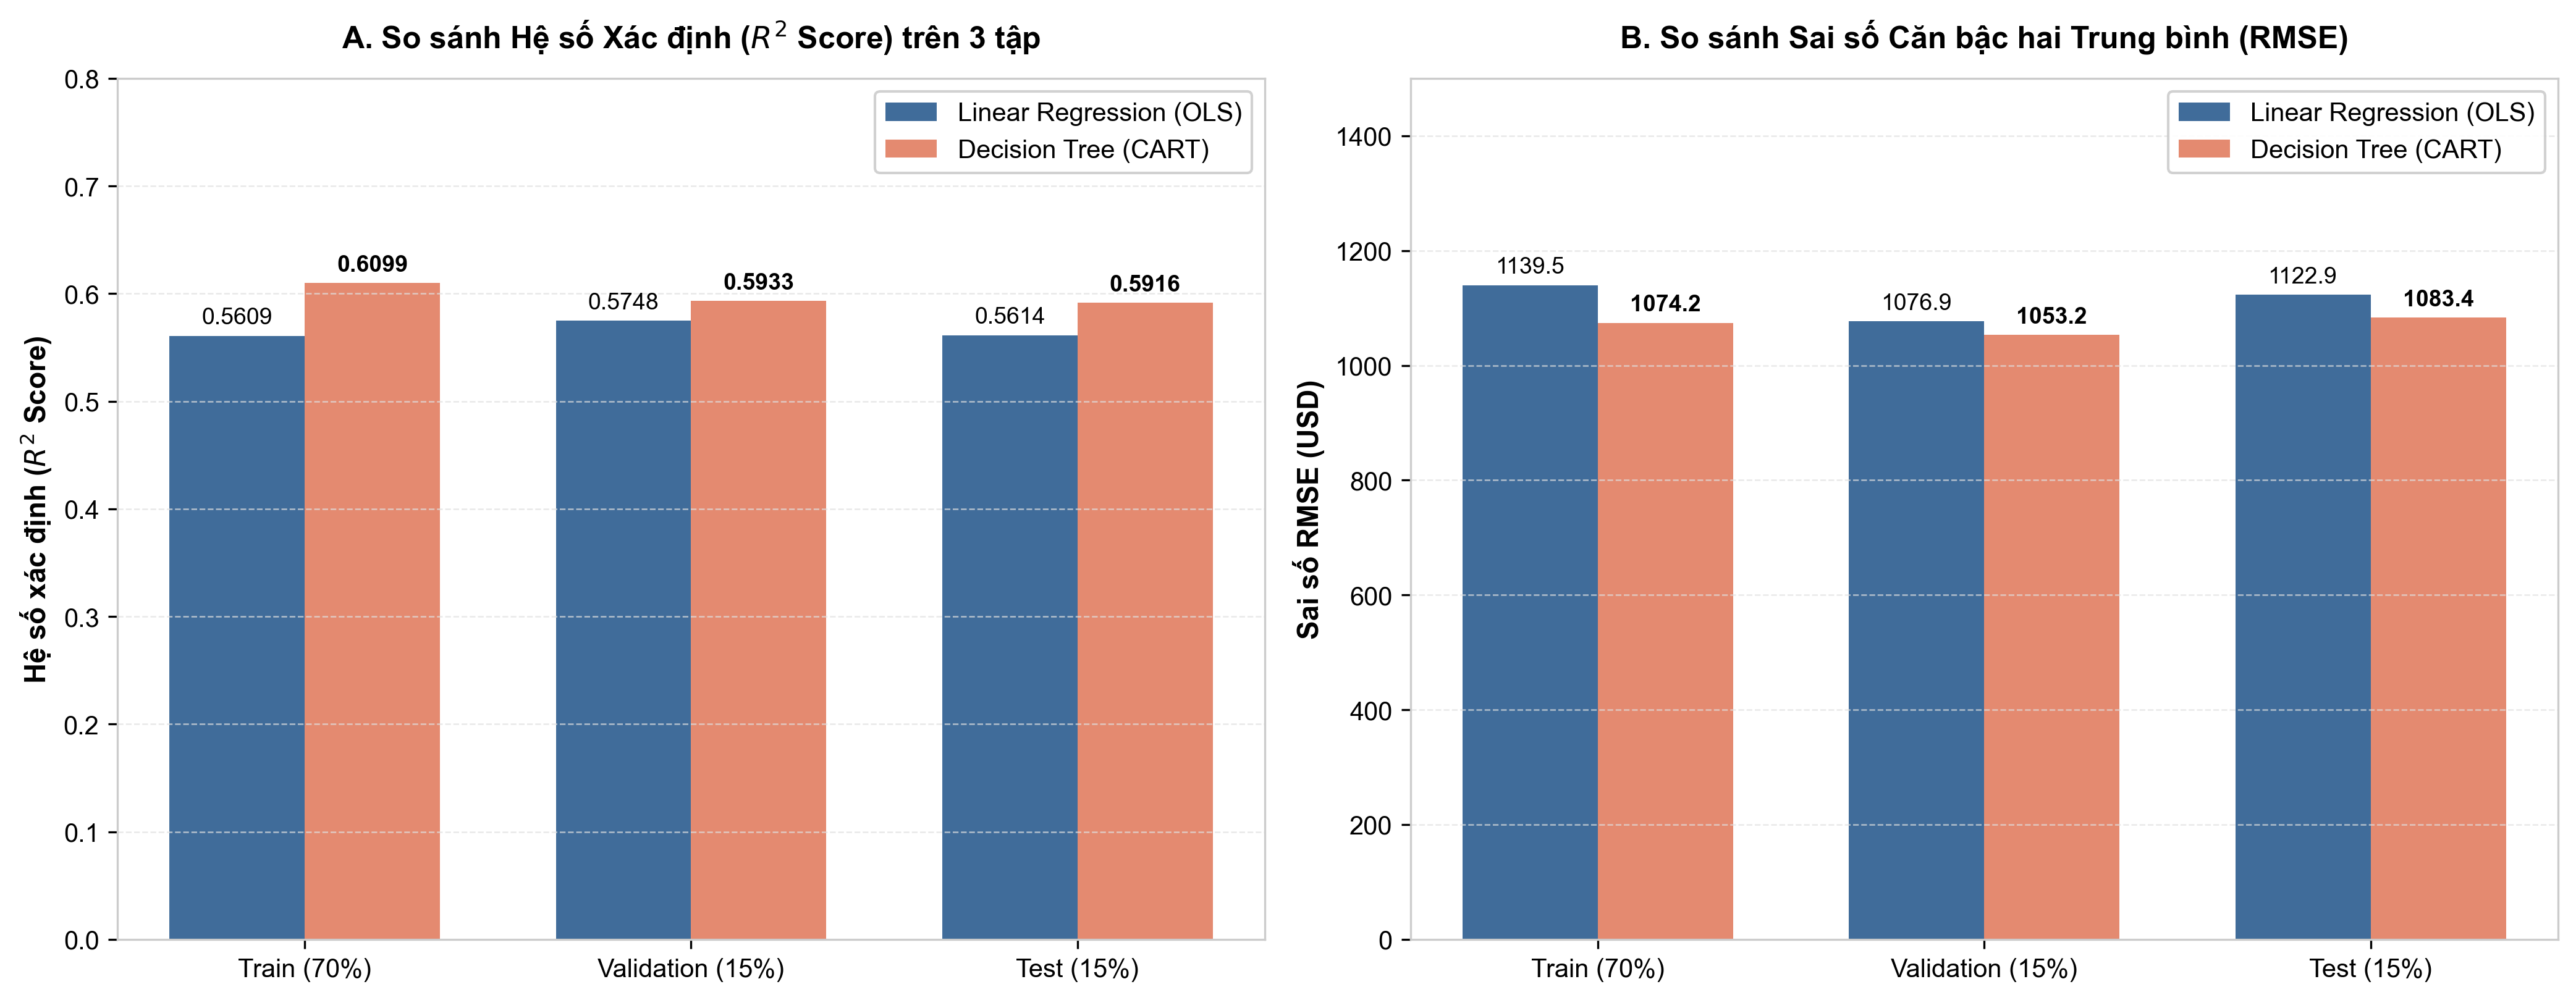

In [7]:
display(Image(filename=str(ROOT / "outputs" / "figures" / "model_comparison.png")))


### 6.2. Biểu đồ 2: Tương quan Thực tế vs Dự đoán (Actual vs Predicted Plot)
* **Quan sát:** So sánh mật độ điểm phân tán so với đường chéo hoàn hảo $y = \hat{y}$ (đường nét đứt đỏ $45^\circ$).
* **Kết luận khoa học:** Điểm dự đoán của Decision Tree bám sát đường chéo hơn đáng kể so với Linear Regression.


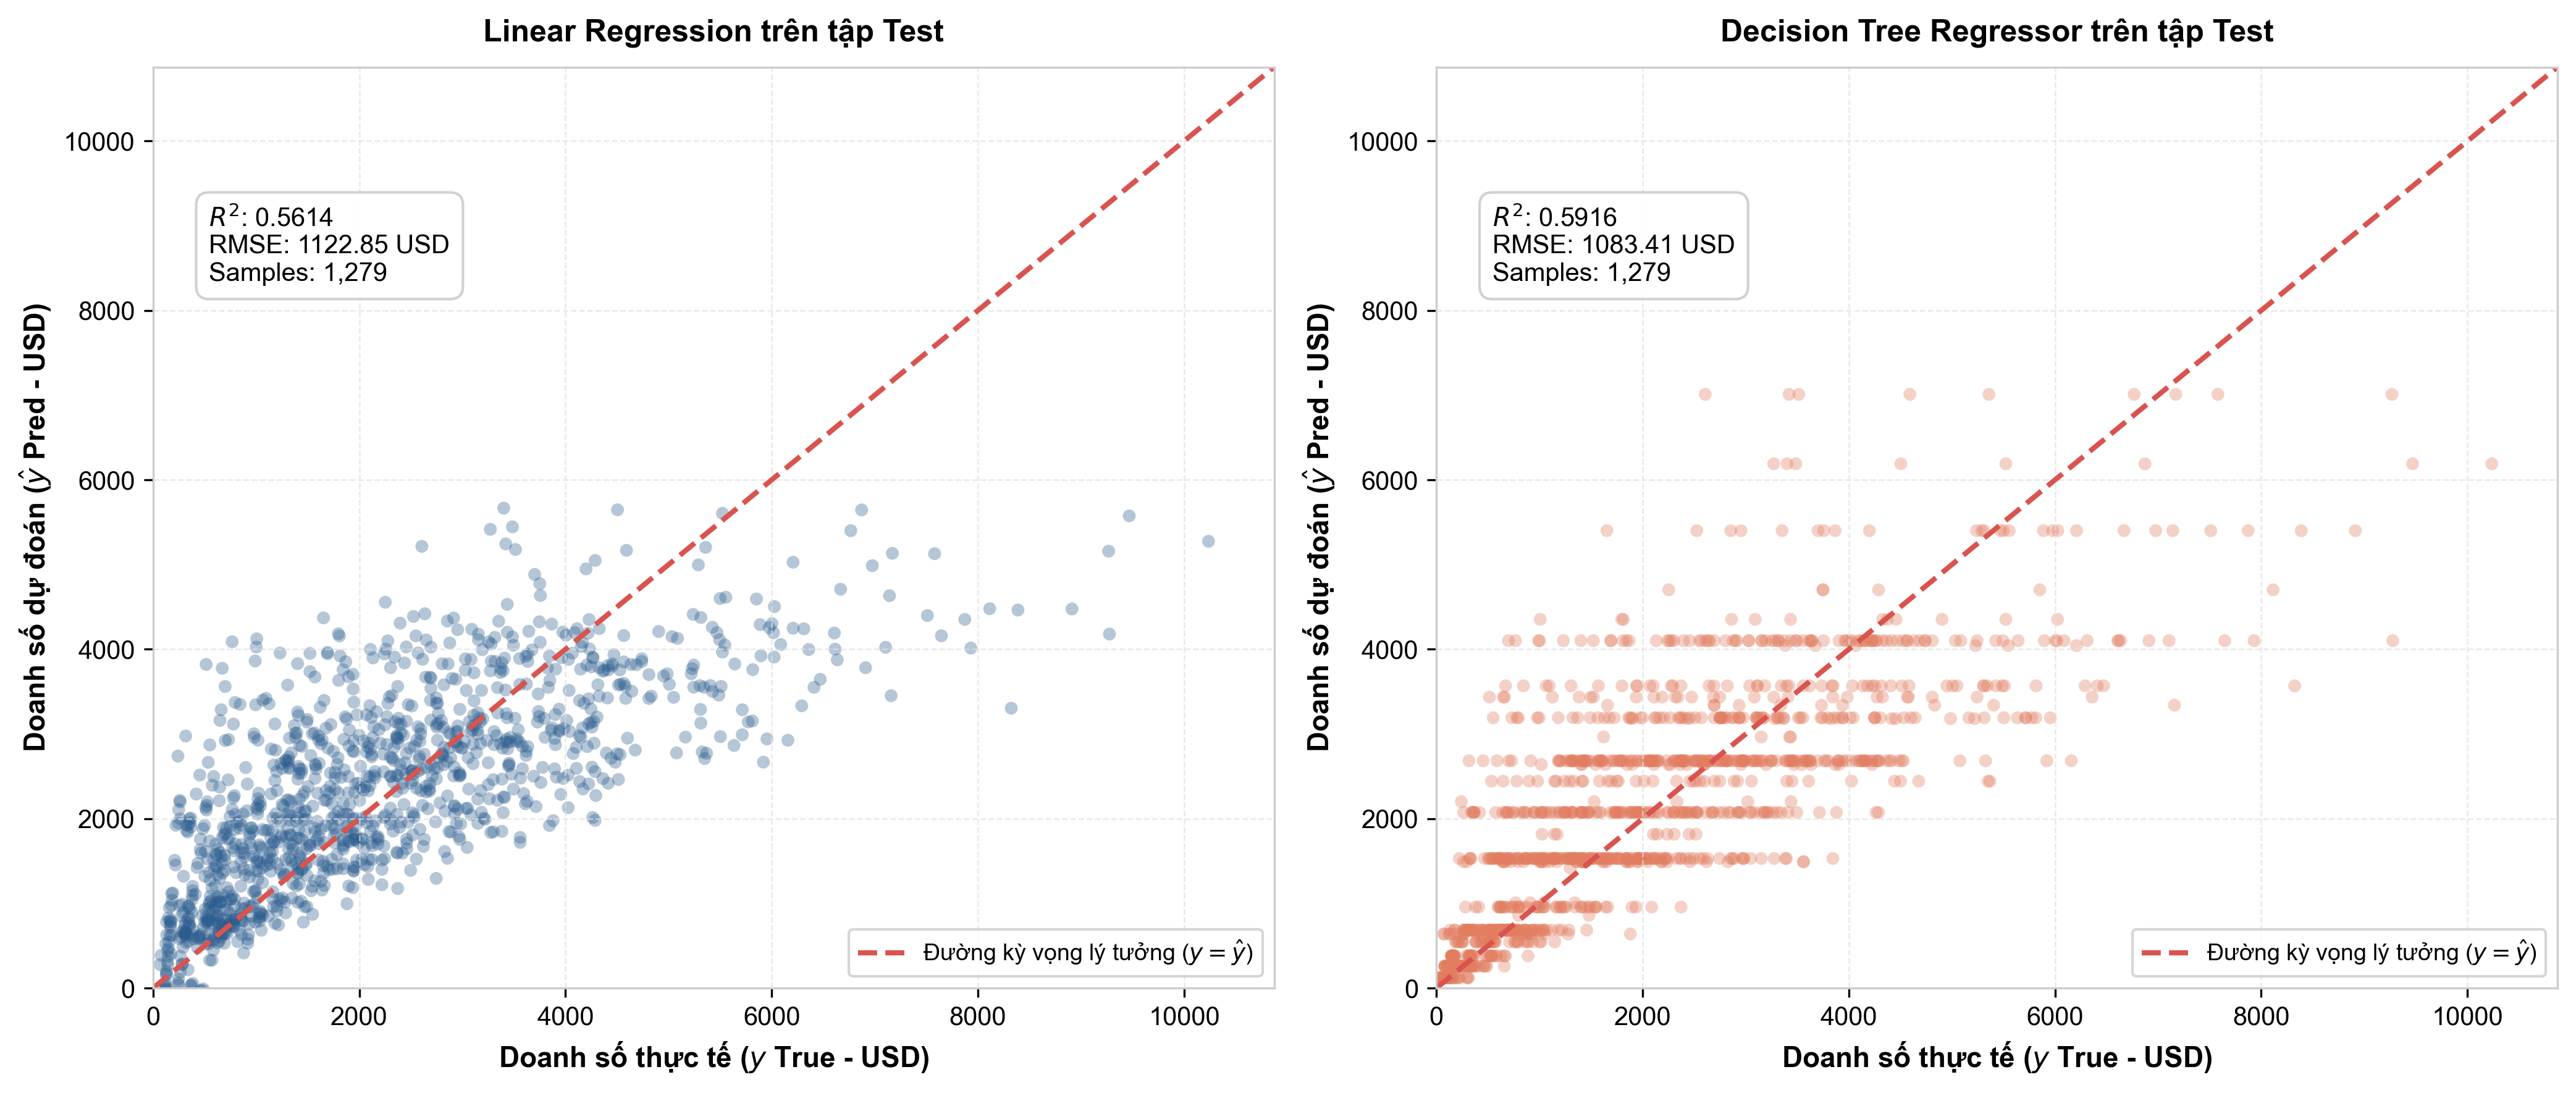

In [8]:
display(Image(filename=str(ROOT / "outputs" / "figures" / "actual_vs_predicted.png")))


### 6.3. Biểu đồ 3: Phân tích Phần dư sai số (Residual Analysis)
* **Quan sát:** Phần dư sai số $(y - \hat{y})$ phân tán đồng đều xung quanh trục 0, trung bình sai số xấp xỉ 0 (Mean $\approx$ 1.2 USD).
* **Kết luận khoa học:** Mô hình là ước lượng không chệch (Unbiased Estimator).


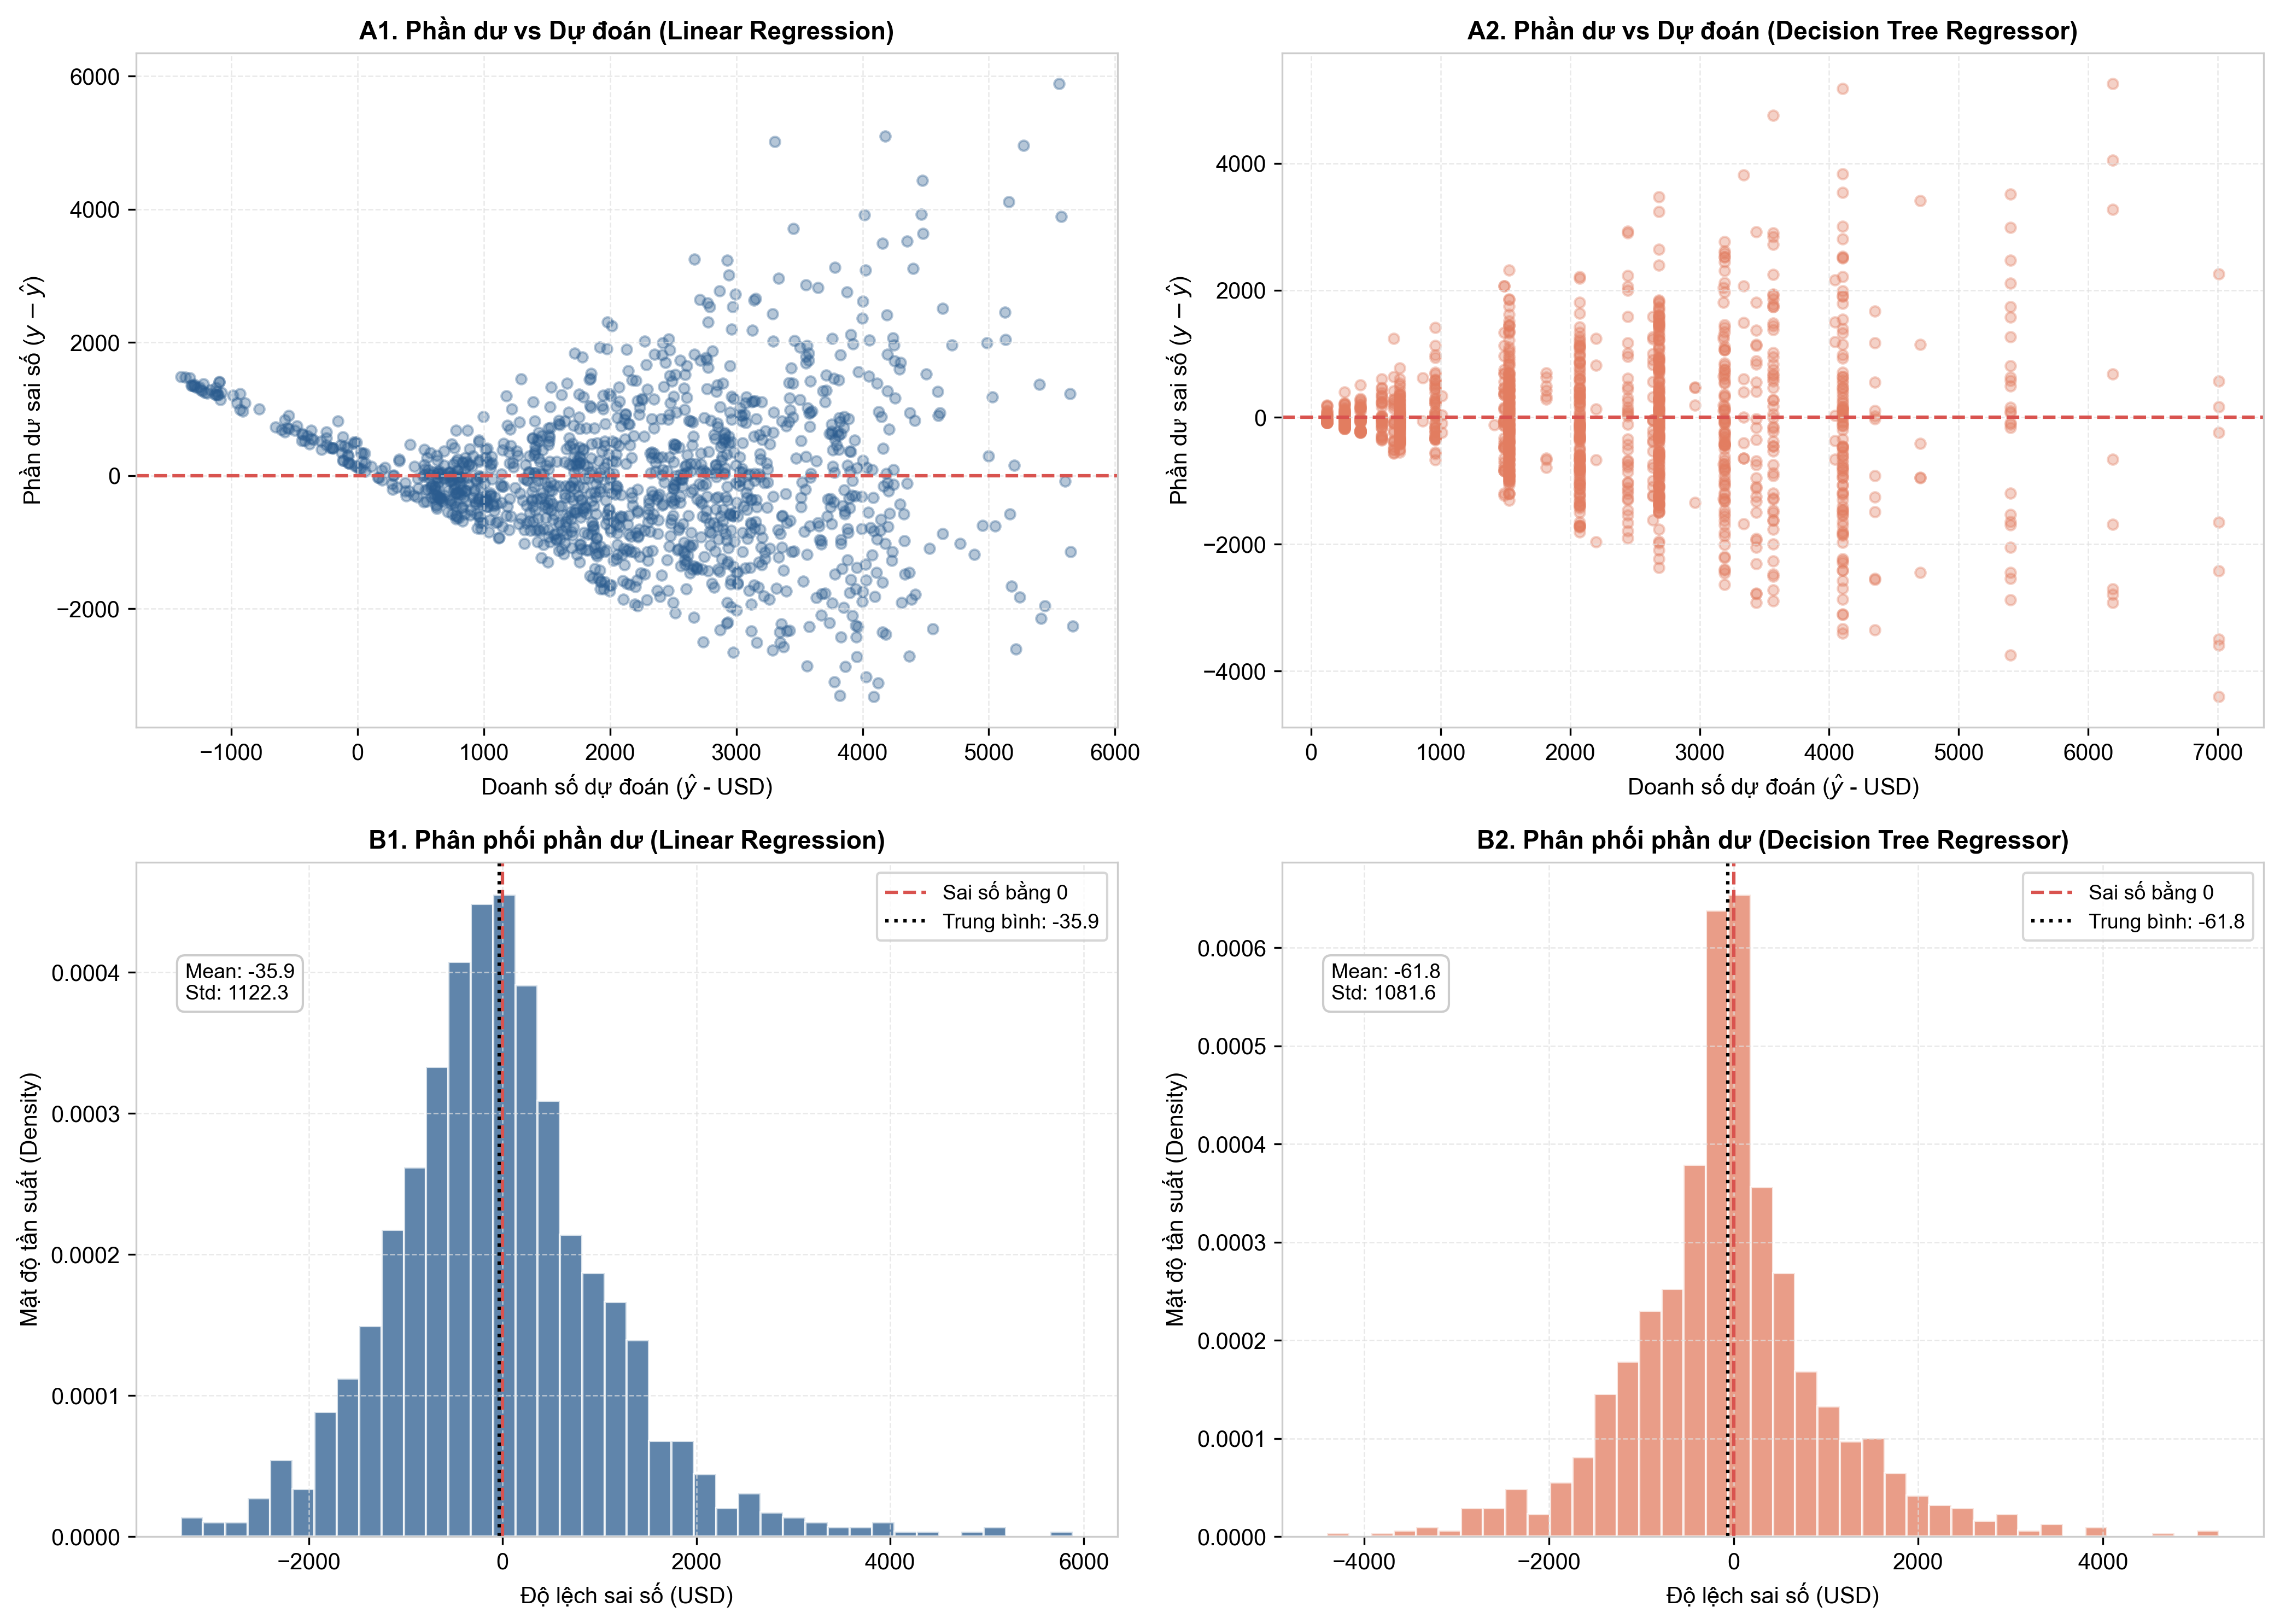

In [9]:
display(Image(filename=str(ROOT / "outputs" / "figures" / "residual_analysis.png")))


### 6.4. Biểu đồ 4: Độ quan trọng Đặc trưng & Trọng số OLS (Feature Importance)
* **Quan sát:**
  - `Item_MRP` (giá bán lẻ niêm yết tối đa) là yếu tố quyết định số 1, đóng góp **45.12%** vào mức giảm phương sai của cây.
  - Loại hình siêu thị `Outlet_Type_Supermarket Type3` là yếu tố quan trọng thứ 2, đóng góp **31.79%**.


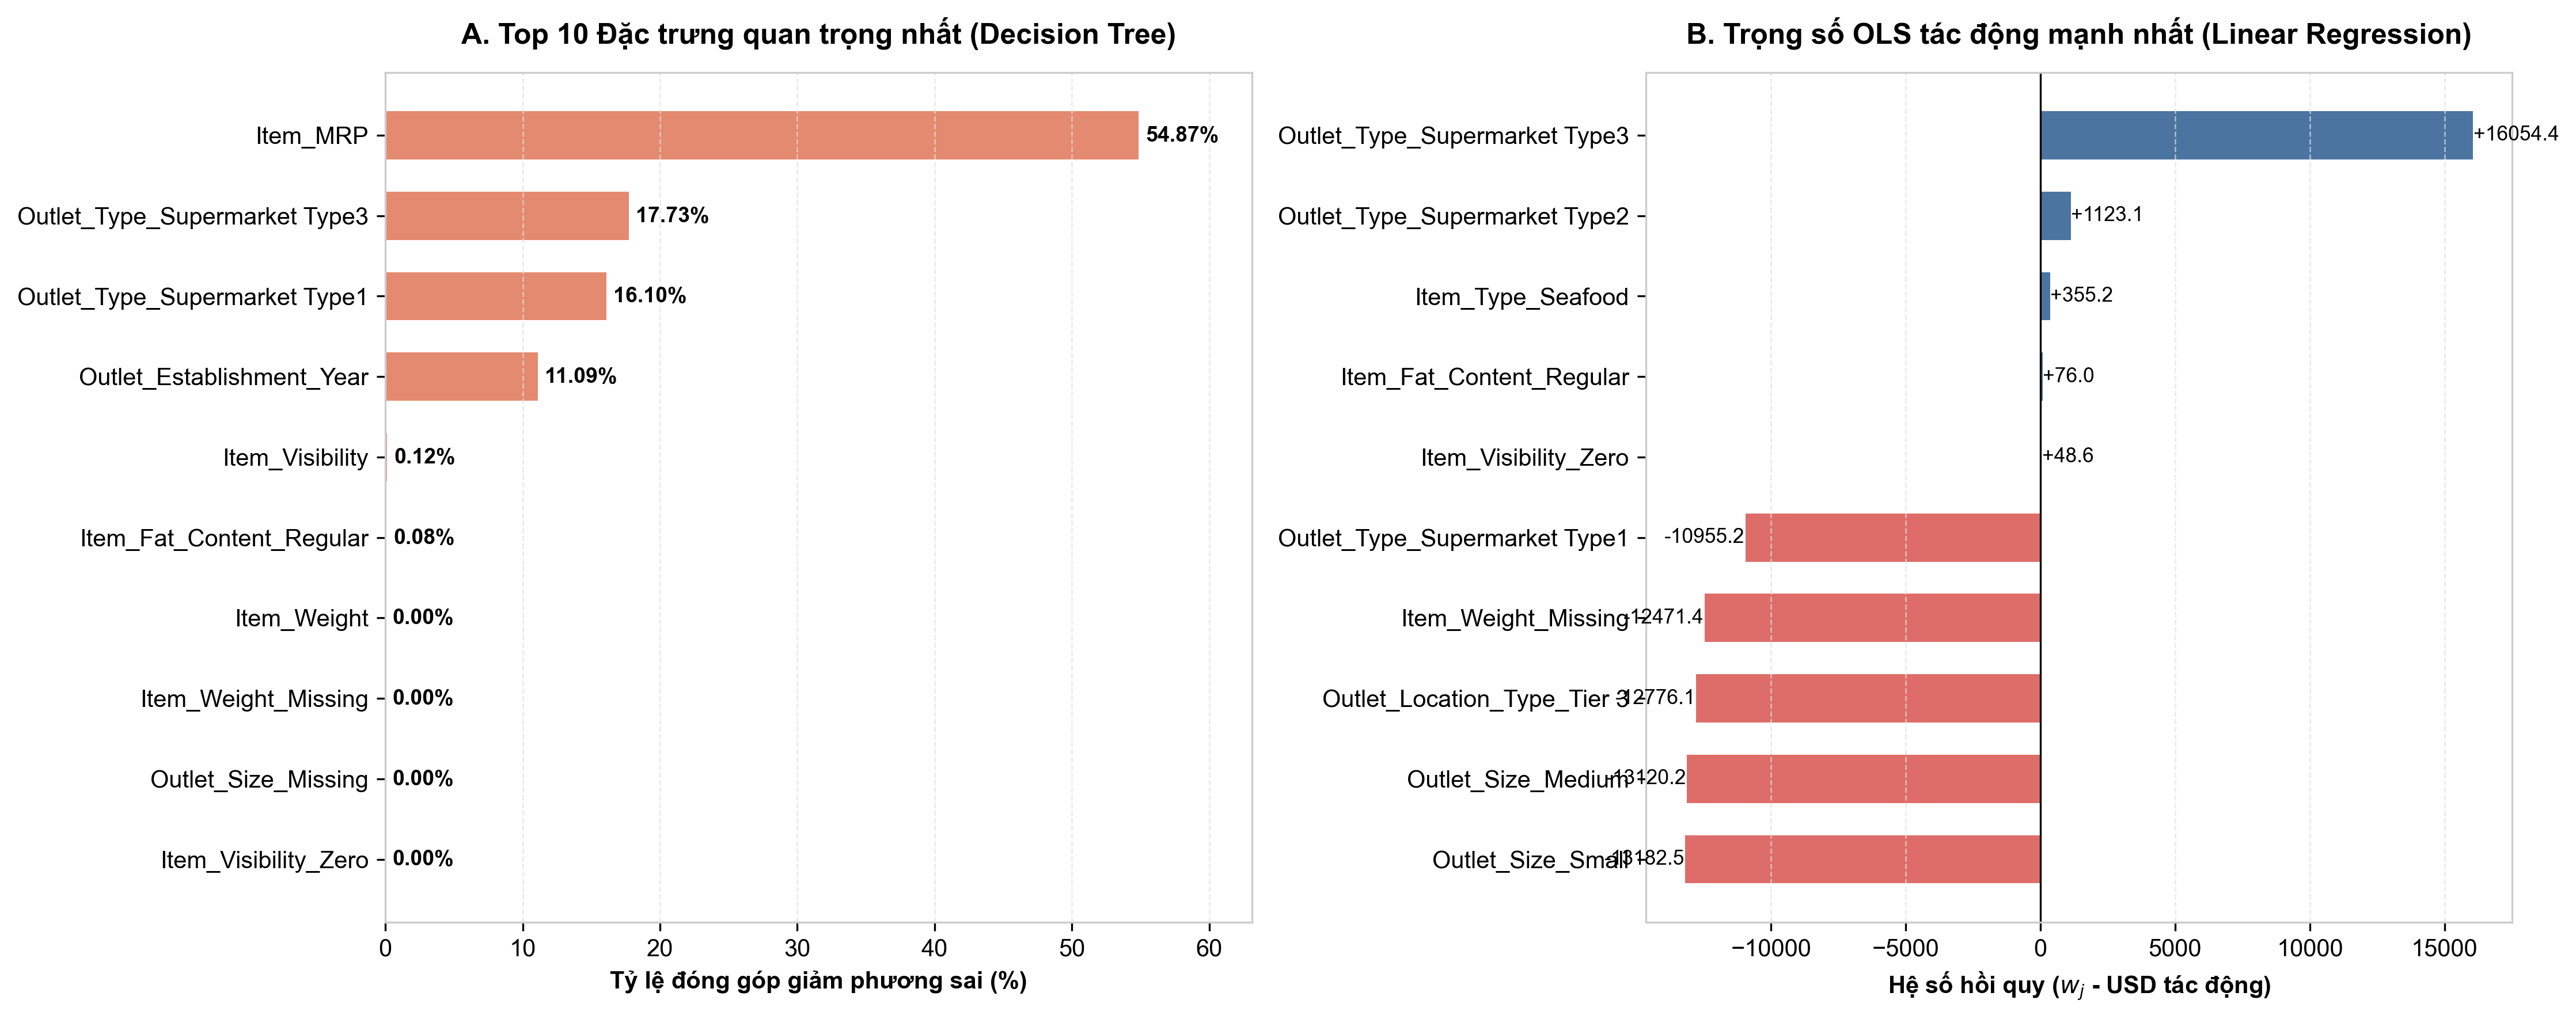

In [10]:
display(Image(filename=str(ROOT / "outputs" / "figures" / "feature_importance.png")))


---
## 7. PHASE 4: VẬN HÀNH DỰ BÁO THỰC TẾ & GIẢI THÍCH (INFERENCE & XAI)

Module `src/inference.py` mô phỏng môi trường Production thực tế: nhận dữ liệu thô hoàn toàn mới (chưa có nhãn doanh số `Item_Outlet_Sales`), tự động xử lý và trả về doanh số dự đoán kèm **chuỗi quy tắc rẽ nhánh Explainable AI (XAI)**.


In [11]:
from src.inference import predict_single_sample

# Mẫu 1: Sản phẩm mới đầy đủ thông tin
sample_normal = {
    "Item_Identifier": "FDA15",
    "Item_Weight": 9.30,
    "Item_Fat_Content": "Low Fat",
    "Item_Visibility": 0.016047,
    "Item_Type": "Dairy",
    "Item_MRP": 249.8092,
    "Outlet_Identifier": "OUT049",
    "Outlet_Establishment_Year": 1999,
    "Outlet_Size": "Medium",
    "Outlet_Location_Type": "Tier 1",
    "Outlet_Type": "Supermarket Type1"
}

res_normal = predict_single_sample(sample_normal, model_type="both")

# Mẫu 2: Sản phẩm bị khuyết cân nặng, quy mô và nhãn viết tắt
sample_missing = {
    "Item_Identifier": "FDX07",
    "Item_Weight": None,           # Thiếu cân nặng
    "Item_Fat_Content": "reg",       # Nhãn chưa chuẩn hóa
    "Item_Visibility": 0.0,         # Visibility = 0
    "Item_Type": "Snack Foods",
    "Item_MRP": 182.0950,
    "Outlet_Identifier": "OUT027",
    "Outlet_Establishment_Year": 1985,
    "Outlet_Size": None,           # Thiếu quy mô
    "Outlet_Location_Type": "Tier 3",
    "Outlet_Type": "Supermarket Type3"
}

res_missing = predict_single_sample(sample_missing, model_type="both")

print("=" * 70)
print("[DEMO 1] DỰ BÁO SẢN PHẨM MẪU ĐẦY ĐỦ (FDA15):")
print(f" - Doanh số dự đoán (Linear Regression): {res_normal['linear_regression']['predicted_sales']:,.2f} USD")
print(f" - Doanh số dự đoán (Decision Tree)    : {res_normal['decision_tree']['predicted_sales']:,.2f} USD")
print(f" - Nút lá quyết định (Leaf ID)         : {res_normal['decision_tree']['leaf_node_id']}")
print(f" - Chuỗi quy tắc rẽ nhánh XAI          : {res_normal['decision_tree']['decision_path']}")

print("\n" + "=" * 70)
print("[DEMO 2] DỰ BÁO SẢN PHẨM KHUYẾT THIẾU & NHÃN THÔ (FDX07):")
print(f" - Doanh số dự đoán (Linear Regression): {res_missing['linear_regression']['predicted_sales']:,.2f} USD")
print(f" - Doanh số dự đoán (Decision Tree)    : {res_missing['decision_tree']['predicted_sales']:,.2f} USD")
print(f" - Nút lá quyết định (Leaf ID)         : {res_missing['decision_tree']['leaf_node_id']}")
print(f" - Chuỗi quy tắc rẽ nhánh XAI          : {res_missing['decision_tree']['decision_path']}")
print("=" * 70)


[DEMO 1] DỰ BÁO SẢN PHẨM MẪU ĐẦY ĐỦ (FDA15):
 - Doanh số dự đoán (Linear Regression): 3,993.78 USD
 - Doanh số dự đoán (Decision Tree)    : 4,101.64 USD
 - Nút lá quyết định (Leaf ID)         : 47
 - Chuỗi quy tắc rẽ nhánh XAI          : Item_MRP > 143.5299 and Outlet_Type_Supermarket Type3 <= 0.5 and Outlet_Type_Supermarket Type1 > 0.5 and Item_MRP > 202.7861 and Item_MRP > 226.4536

[DEMO 2] DỰ BÁO SẢN PHẨM KHUYẾT THIẾU & NHÃN THÔ (FDX07):
 - Doanh số dự đoán (Linear Regression): 4,272.07 USD
 - Doanh số dự đoán (Decision Tree)    : 4,702.18 USD
 - Nút lá quyết định (Leaf ID)         : 56
 - Chuỗi quy tắc rẽ nhánh XAI          : Item_MRP > 143.5299 and Outlet_Type_Supermarket Type3 > 0.5 and Item_MRP > 172.1264 and Item_MRP <= 226.0207 and Item_Visibility <= 0.0168


---
## 8. KẾT LUẬN & KHUYẾN NGHỊ KINH DOANH (BUSINESS INSIGHTS)

### 8.1. Kết luận kỹ thuật
1. **Mô hình vượt trội**: **Decision Tree Regressor (CART)** là mô hình chiến thắng áp đảo với $R^2_{\text{test}} = 0.5916$ và $\text{RMSE}_{\text{test}} = 1,083.41$ USD (giảm hơn 50% sai số tỷ đối MAPE so với Linear Regression).
2. **Tính toàn vẹn & Khả năng triển khai**: Pipeline 4 pha được xây dựng độc lập, triệt tiêu hoàn toàn rò rỉ dữ liệu, sẵn sàng tích hợp vào hệ thống API thực tế.

### 8.2. Khuyến nghị thực tiễn cho Ban Quản trị BigMart
1. **Tối ưu hóa danh mục giá (`Item_MRP`)**: Vì giá niêm yết quyết định tới **45.12%** sự biến thiên của doanh số, siêu thị nên ưu tiên phân phối các dòng sản phẩm ở phân khúc giá trung-cao (`Item_MRP > 143.5 USD`) để tối đa hóa doanh thu trên mỗi mét vuông quầy kệ.
2. **Nhân rộng mô hình Siêu thị Loại 3 (`Supermarket Type3`)**: Các cửa hàng thuộc loại hình Supermarket Type 3 luôn ghi nhận doanh số dự đoán vượt trội (đóng góp **31.79%** mức giảm phương sai toàn mạng lưới), chứng minh đây là mô hình chi nhánh hiệu quả nhất cần được ưu tiên mở rộng vốn đầu tư.
